<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 4 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Réalisez une étude de santé publique avec R ou Python
</h2>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner codes, textes et graphique.

Cet outil est formidable pour plusieurs raisons:

+ il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'un instruction, de la corriger si nécessaire.
+ De rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ d'agrémenter de graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandée.

Et garder à l'esprit, qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



Note jeremy 
Est ce qu'il faut faire le calcul de la sous nutrition sur les pays qu'on a ? 
Est ce qu'il faut faire des graphiques ?
Rajouter le soja
La liste des céréales est difficile a trouver ...

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Importation des librairies</h3>
</div>

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Librairies utiles pour la création de la carte (analyse complémentaire)
import folium
import requests
from branca.colormap import linear

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Chargement des fichiers Excel</h3>
</div>

In [2]:
#Importation du fichier population.csv
population = pd.read_csv('population.csv')

#Importation du fichier dispo_alimentaire.csv
dispo_alimentaire = pd.read_csv('dispo_alimentaire.csv')

#Importation du fichier aide_alimentaire.csv
aide_alimentaire = pd.read_csv('aide_alimentaire.csv')

#Importation du fichier sous_nutrition.csv
sous_nutrition = pd.read_csv('sous_nutrition.csv')

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Analyse exploratoire du fichier population</h3>
</div>

In [3]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(population.shape[0]))
print("Le tableau comporte {} colonne(s)".format(population.shape[1]))

Le tableau comporte 1416 observation(s) ou article(s)
Le tableau comporte 3 colonne(s)


In [4]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(population.shape[1]))
#La nature des données dans chacune des colonnes
print(population.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
for colonne in population.columns:
    print(f"{colonne}: {population[colonne].nunique()} valeurs uniques")

Le tableau comporte 3 colonne(s)
Zone       object
Année       int64
Valeur    float64
dtype: object
Zone: 236 valeurs uniques
Année: 6 valeurs uniques
Valeur: 1413 valeurs uniques


In [5]:
#Affichage les 5 premières lignes de la table
print(population.head())

          Zone  Année     Valeur
0  Afghanistan   2013  32269.589
1  Afghanistan   2014  33370.794
2  Afghanistan   2015  34413.603
3  Afghanistan   2016  35383.032
4  Afghanistan   2017  36296.113


In [6]:
#Nous allons harmoniser les unités. Pour cela, nous avons décidé de multiplier la population par 1000
#Multiplication de la colonne valeur par 1000
population['Valeur'] = population['Valeur'] * 1000

In [7]:
#changement du nom de la colonne Valeur par Population
population.rename(columns={'Valeur': 'Population'}, inplace=True)

In [8]:
#Affichage les 5 premières lignes de la table pour voir les modifications
print(population.head())

          Zone  Année  Population
0  Afghanistan   2013  32269589.0
1  Afghanistan   2014  33370794.0
2  Afghanistan   2015  34413603.0
3  Afghanistan   2016  35383032.0
4  Afghanistan   2017  36296113.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Analyse exploratoire du fichier disponibilité alimentaire</h3>
</div>

In [9]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(dispo_alimentaire.shape[0]))
print("Le tableau comporte {} colonne(s)".format(dispo_alimentaire.shape[1]))

Le tableau comporte 15605 observation(s) ou article(s)
Le tableau comporte 18 colonne(s)


In [10]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(dispo_alimentaire.shape[1]))

Le tableau comporte 18 colonne(s)


In [11]:
#Affichage les 5 premières lignes de la table
print(dispo_alimentaire.head())

          Zone                Produit   Origine  Aliments pour animaux  \
0  Afghanistan       Abats Comestible   animale                    NaN   
1  Afghanistan        Agrumes, Autres  vegetale                    NaN   
2  Afghanistan  Aliments pour enfants  vegetale                    NaN   
3  Afghanistan                 Ananas  vegetale                    NaN   
4  Afghanistan                Bananes  vegetale                    NaN   

   Autres Utilisations  Disponibilité alimentaire (Kcal/personne/jour)  \
0                  NaN                                             5.0   
1                  NaN                                             1.0   
2                  NaN                                             1.0   
3                  NaN                                             0.0   
4                  NaN                                             4.0   

   Disponibilité alimentaire en quantité (kg/personne/an)  \
0                                               1

In [12]:
#remplacement des NaN dans le dataset par des 0
dispo_alimentaire.fillna(0, inplace=True)

In [13]:
#multiplication de toutes les lignes contenant des milliers de tonnes en Kg 
dispo_alimentaire['Aliments pour animaux'] = dispo_alimentaire['Aliments pour animaux'] * 1000
dispo_alimentaire['Autres Utilisations'] = dispo_alimentaire['Autres Utilisations'] * 1000
dispo_alimentaire['Disponibilité intérieure'] = dispo_alimentaire['Disponibilité intérieure'] * 1000
dispo_alimentaire['Exportations - Quantité'] = dispo_alimentaire['Exportations - Quantité'] * 1000
dispo_alimentaire['Importations - Quantité'] = dispo_alimentaire['Importations - Quantité'] * 1000
dispo_alimentaire['Nourriture'] = dispo_alimentaire['Nourriture'] * 1000
dispo_alimentaire['Pertes'] = dispo_alimentaire['Pertes'] * 1000
dispo_alimentaire['Production'] = dispo_alimentaire['Production'] * 1000
dispo_alimentaire['Semences'] = dispo_alimentaire['Semences'] * 1000
dispo_alimentaire['Traitement'] = dispo_alimentaire['Traitement'] * 1000
dispo_alimentaire['Variation de stock'] = dispo_alimentaire['Variation de stock'] * 1000

In [14]:
#Affichage les 5 premières lignes de la table
print(dispo_alimentaire.head())

          Zone                Produit   Origine  Aliments pour animaux  \
0  Afghanistan       Abats Comestible   animale                    0.0   
1  Afghanistan        Agrumes, Autres  vegetale                    0.0   
2  Afghanistan  Aliments pour enfants  vegetale                    0.0   
3  Afghanistan                 Ananas  vegetale                    0.0   
4  Afghanistan                Bananes  vegetale                    0.0   

   Autres Utilisations  Disponibilité alimentaire (Kcal/personne/jour)  \
0                  0.0                                             5.0   
1                  0.0                                             1.0   
2                  0.0                                             1.0   
3                  0.0                                             0.0   
4                  0.0                                             4.0   

   Disponibilité alimentaire en quantité (kg/personne/an)  \
0                                               1

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier aide alimentaire</h3>
</div>

In [15]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(aide_alimentaire.shape[0]))
print("Le tableau comporte {} colonne(s)".format(aide_alimentaire.shape[1]))

Le tableau comporte 1475 observation(s) ou article(s)
Le tableau comporte 4 colonne(s)


In [16]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(aide_alimentaire.shape[1]))

Le tableau comporte 4 colonne(s)


In [17]:
#Affichage les 5 premières lignes de la table
print(aide_alimentaire.head())

  Pays bénéficiaire  Année              Produit  Valeur
0       Afghanistan   2013  Autres non-céréales     682
1       Afghanistan   2014  Autres non-céréales     335
2       Afghanistan   2013         Blé et Farin   39224
3       Afghanistan   2014         Blé et Farin   15160
4       Afghanistan   2013             Céréales   40504


In [18]:
#changement du nom de la colonne Pays bénéficiaire par Zone
aide_alimentaire.rename(columns={'Pays bénéficiaire': 'Zone'}, inplace=True)

In [19]:
#Multiplication de la colonne Aide_alimentaire qui contient des tonnes par 1000 pour avoir des kg
aide_alimentaire['Valeur'] = aide_alimentaire['Valeur'] * 1000

In [20]:
#Affichage les 5 premières lignes de la table
print(aide_alimentaire.head())

          Zone  Année              Produit    Valeur
0  Afghanistan   2013  Autres non-céréales    682000
1  Afghanistan   2014  Autres non-céréales    335000
2  Afghanistan   2013         Blé et Farin  39224000
3  Afghanistan   2014         Blé et Farin  15160000
4  Afghanistan   2013             Céréales  40504000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.4 - Analyse exploratoire du fichier sous nutrition</h3>
</div>

In [21]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(sous_nutrition.shape[0]))
print("Le tableau comporte {} colonne(s)".format(sous_nutrition.shape[1]))

Le tableau comporte 1218 observation(s) ou article(s)
Le tableau comporte 3 colonne(s)


In [22]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(sous_nutrition.shape[1]))

Le tableau comporte 3 colonne(s)


In [23]:
#Afficher les 5 premières lignes de la table
print(sous_nutrition.head())

          Zone      Année Valeur
0  Afghanistan  2012-2014    8.6
1  Afghanistan  2013-2015    8.8
2  Afghanistan  2014-2016    8.9
3  Afghanistan  2015-2017    9.7
4  Afghanistan  2016-2018   10.5


In [24]:
#Conversion de la colonne (avec l'argument errors=coerce qui permet de convertir automatiquement les lignes qui ne sont pas des nombres en NaN)
sous_nutrition['Valeur'] = pd.to_numeric(sous_nutrition['Valeur'], errors='coerce')
#Puis remplacement des NaN en 0
sous_nutrition.fillna(0, inplace=True)

In [25]:
#changement du nom de la colonne Valeur par sous_nutrition
sous_nutrition.rename(columns={'Valeur': 'sous_nutrition'}, inplace=True)

In [26]:
#Multiplication de la colonne sous_nutrition par 1000000
sous_nutrition['sous_nutrition'] = sous_nutrition['sous_nutrition'] * 1000000

In [27]:
#Afficher les 5 premières lignes de la table
print(sous_nutrition.head())

          Zone      Année  sous_nutrition
0  Afghanistan  2012-2014       8600000.0
1  Afghanistan  2013-2015       8800000.0
2  Afghanistan  2014-2016       8900000.0
3  Afghanistan  2015-2017       9700000.0
4  Afghanistan  2016-2018      10500000.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.1 - Proportion de personnes en sous nutrition</h3>
</div>

In [28]:
# Il faut tout d'abord faire une jointure entre la table population et la table sous nutrition, en ciblant l'année 2017
proportion_sous_nutrition = pd.merge(population, sous_nutrition, on='Zone', how='inner')
proportion_sous_nutrition_2017 = proportion_sous_nutrition[
    (proportion_sous_nutrition['Année_y'] == '2016-2018') & (proportion_sous_nutrition['Année_x'] == 2017)]

In [29]:
#Affichage du dataset
print(proportion_sous_nutrition_2017.head())

               Zone  Année_x  Population    Année_y  sous_nutrition
28      Afghanistan     2017  36296113.0  2016-2018      10500000.0
64   Afrique du Sud     2017  57009756.0  2016-2018       3100000.0
100         Albanie     2017   2884169.0  2016-2018        100000.0
136         Algérie     2017  41389189.0  2016-2018       1300000.0
172       Allemagne     2017  82658409.0  2016-2018             0.0


In [30]:
#Calcul du nombre de personnes en sous-nutrition et création de l'indicateur indicateur_sous_nutrition
nombre_personnes_sous_nutrition = round(proportion_sous_nutrition_2017['sous_nutrition'].sum())
indicateur_sous_nutrition = round((proportion_sous_nutrition_2017['sous_nutrition'].sum() / proportion_sous_nutrition_2017['Population'].sum())*100,2)
print(f"Le nombre d'humains en sous-nutrition est de : {nombre_personnes_sous_nutrition}, cela correspond à {indicateur_sous_nutrition}% de la population mondiale.")

Le nombre d'humains en sous-nutrition est de : 535700000, cela correspond à 7.1% de la population mondiale.


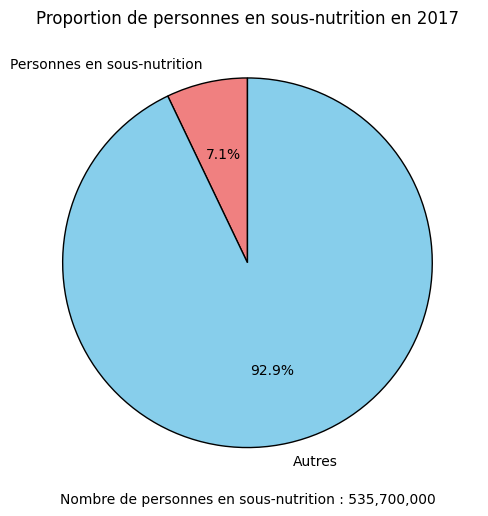

In [31]:
# Calcul des parts du diagramme circulaire
data = [indicateur_sous_nutrition, 100 - indicateur_sous_nutrition]
labels = ['Personnes en sous-nutrition', 'Autres']
colors = ['lightcoral', 'skyblue']

# Création du diagramme circulaire
plt.figure(figsize=(6, 6))
plt.pie(data, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors, wedgeprops={'edgecolor': 'black'})
plt.title("Proportion de personnes en sous-nutrition en 2017")
plt.text(0, -1.3, f"Nombre de personnes en sous-nutrition : {nombre_personnes_sous_nutrition:,}",
         ha='center', fontsize=10, color='black')

# Exportation de l'image
plt.savefig("3.1.png", dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.2 - Nombre théorique de personnes qui pourraient être nourries en 2017</h3>
</div>

Combien mange en moyenne un être humain ? Source => https://www.vidal.fr/sante/nutrition/equilibre-alimentaire-adulte/recommandations-nutritionnelles-adulte.html
Pour un homme adulte, l’apport conseillé en énergie est, en moyenne, de 2 400 à 2 600 calories par jour, selon l’activité. Pour une femme adulte, il est de 1 800 à 2 200 calories.

In [32]:
nombre_personnes_2017 = 7400000000 #Nombre de personnes sur Terre en 2017

In [33]:
#On commence par faire une jointure entre le data frame population et Dispo_alimentaire afin d'ajouter dans ce dernier la population
dispo_alimentaire_population = pd.merge(population, dispo_alimentaire, on='Zone', how='inner')
dispo_alimentaire_population_2017 = dispo_alimentaire_population[dispo_alimentaire_population['Année'] == 2017]

In [34]:
#Affichage du nouveau dataframe
print(dispo_alimentaire_population_2017.head())

            Zone  Année  Population                Produit   Origine  \
240  Afghanistan   2017  36296113.0       Abats Comestible   animale   
241  Afghanistan   2017  36296113.0        Agrumes, Autres  vegetale   
242  Afghanistan   2017  36296113.0  Aliments pour enfants  vegetale   
243  Afghanistan   2017  36296113.0                 Ananas  vegetale   
244  Afghanistan   2017  36296113.0                Bananes  vegetale   

     Aliments pour animaux  Autres Utilisations  \
240                    0.0                  0.0   
241                    0.0                  0.0   
242                    0.0                  0.0   
243                    0.0                  0.0   
244                    0.0                  0.0   

     Disponibilité alimentaire (Kcal/personne/jour)  \
240                                             5.0   
241                                             1.0   
242                                             1.0   
243                                     

In [35]:
# Copie de dispo_alimentaire_population_2017
dispo_alimentaire_population_2017 = dispo_alimentaire_population_2017.copy()

#Création de la colonne dispo_kcal avec calcul des kcal disponibles mondialement
dispo_alimentaire_population_2017.loc[:, 'dispo_kcal'] = (
dispo_alimentaire_population_2017['Disponibilité alimentaire (Kcal/personne/jour)'] * 
dispo_alimentaire_population_2017['Population']
)

In [36]:
print(dispo_alimentaire_population_2017[['Zone', 'dispo_kcal']].head())

            Zone   dispo_kcal
240  Afghanistan  181480565.0
241  Afghanistan   36296113.0
242  Afghanistan   36296113.0
243  Afghanistan          0.0
244  Afghanistan  145184452.0


In [37]:
#Calcul du nombre d'humains pouvant être nourris
nb_humains_nourris = round(dispo_alimentaire_population_2017['dispo_kcal'].sum() / 2250)
print(f"Le nombre d'humains pouvant être nourris est de : {nb_humains_nourris}")

Le nombre d'humains pouvant être nourris est de : 9297326501


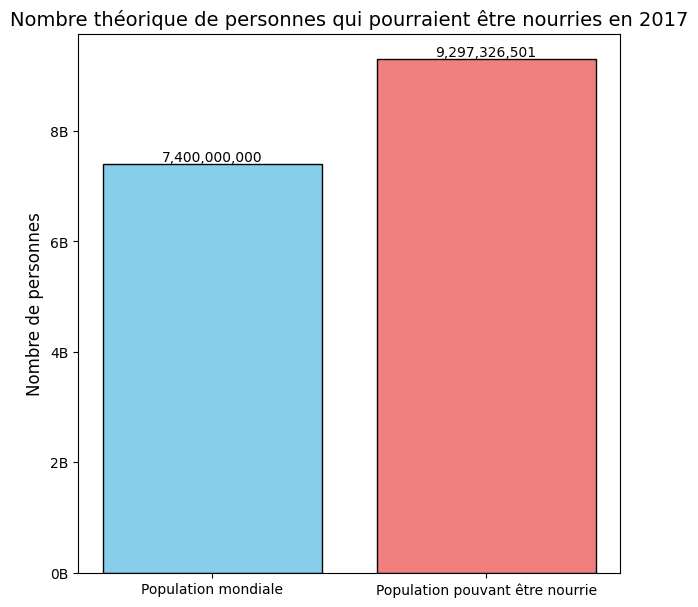

In [38]:
# Données pour le graphique
categories = ['Population mondiale', 'Population pouvant être nourrie']
valeurs = [nombre_personnes_2017, nb_humains_nourris]
colors = ['skyblue', 'lightcoral']

# Création du graphique à barres
plt.figure(figsize=(7, 7))
bars = plt.bar(categories, valeurs, color=colors, edgecolor = 'black')

# Ajout des valeurs sur les barres
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height, f'{height:,}', ha='center', va='bottom', fontsize=10)

# Titre et labels
plt.title("Nombre théorique de personnes qui pourraient être nourries en 2017", fontsize=14)
plt.ylabel("Nombre de personnes", fontsize=12)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x / 1e9:.0f}B'))

# Exportation de l'image
plt.savefig("3.2.png", dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.3 - Nombre théorique de personnes qui pourraient être nourries avec les produits végétaux</h3>
</div>

In [39]:
#Transfert des données avec les végétaux dans un nouveau dataframe
dispo_alimentaire_population_vegetaux_2017 =  dispo_alimentaire_population_2017[dispo_alimentaire_population_2017['Origine'] == 'vegetale']

In [40]:
#Affichage du nouveau dataframe
print(dispo_alimentaire_population_vegetaux_2017.head())

            Zone  Année  Population                Produit   Origine  \
241  Afghanistan   2017  36296113.0        Agrumes, Autres  vegetale   
242  Afghanistan   2017  36296113.0  Aliments pour enfants  vegetale   
243  Afghanistan   2017  36296113.0                 Ananas  vegetale   
244  Afghanistan   2017  36296113.0                Bananes  vegetale   
246  Afghanistan   2017  36296113.0                  Bière  vegetale   

     Aliments pour animaux  Autres Utilisations  \
241                    0.0                  0.0   
242                    0.0                  0.0   
243                    0.0                  0.0   
244                    0.0                  0.0   
246                    0.0                  0.0   

     Disponibilité alimentaire (Kcal/personne/jour)  \
241                                             1.0   
242                                             1.0   
243                                             0.0   
244                                     

In [41]:
#Calcul du nombre d'humains pouvant être nourris avec les végétaux
nb_humains_nourris_vegetaux = round(dispo_alimentaire_population_vegetaux_2017['dispo_kcal'].sum() / 2250)
print(f"Le nombre d'humains pouvant être nourris avec les végétaux est de : {nb_humains_nourris_vegetaux}")

Le nombre d'humains pouvant être nourris avec les végétaux est de : 7671450761


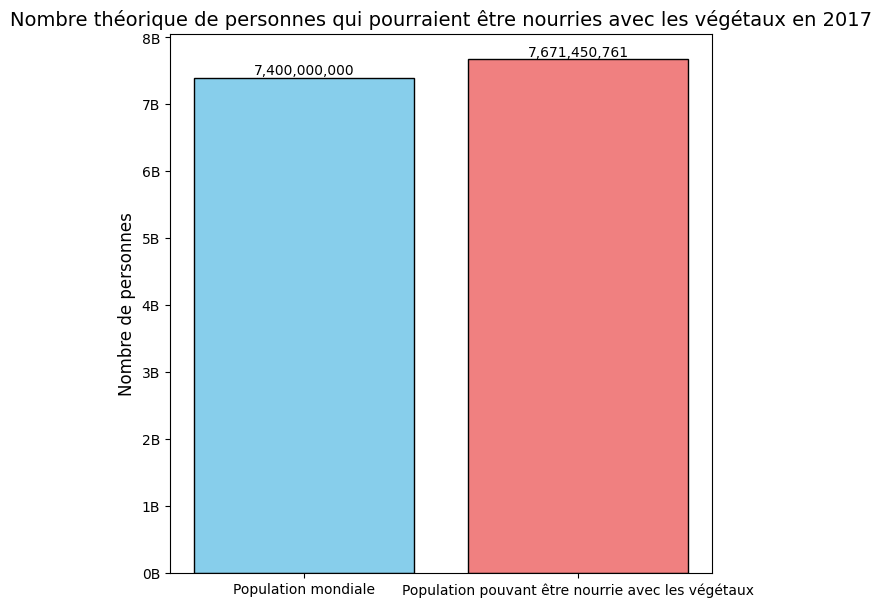

In [42]:
# Données pour le graphique
categories = ['Population mondiale', 'Population pouvant être nourrie avec les végétaux']
valeurs = [nombre_personnes_2017, nb_humains_nourris_vegetaux]
colors = ['skyblue', 'lightcoral']

# Création du graphique à barres
plt.figure(figsize=(7, 7))
bars = plt.bar(categories, valeurs, color=colors, edgecolor = 'black')

# Ajout des valeurs sur les barres
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height, f'{height:,}', ha='center', va='bottom', fontsize=10)

# Titre et labels
plt.title("Nombre théorique de personnes qui pourraient être nourries avec les végétaux en 2017", fontsize=14)
plt.ylabel("Nombre de personnes", fontsize=12)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x / 1e9:.0f}B'))

# Exportation de l'image
plt.savefig("3.3.png", dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.4 - Utilisation de la disponibilité intérieure</h3>
</div>

In [43]:
#Calcul de la disponibilité totale
disponibilité_totale = round(dispo_alimentaire_population_2017['Production'].sum() +
                                    dispo_alimentaire_population_2017['Importations - Quantité'].sum() -
                                    dispo_alimentaire_population_2017['Exportations - Quantité'].sum() +
                                    dispo_alimentaire_population_2017['Variation de stock'].sum() )
print(f"La disponibilité totale mondiale est de : {disponibilité_totale}")

La disponibilité totale mondiale est de : 9734105000


In [44]:
#création d'une boucle for pour afficher les différentes valeurs de disponibilité
colonnes = ['Aliments pour animaux', 'Nourriture', 'Pertes', 'Semences', 'Traitement', 'Autres Utilisations']

for colonne in colonnes:
    valeur_colonne = dispo_alimentaire_population_2017[colonne].sum()
    print(f"La disponibilité mondiale pour '{colonne}' est de : {valeur_colonne}")

La disponibilité mondiale pour 'Aliments pour animaux' est de : 1288002000.0
La disponibilité mondiale pour 'Nourriture' est de : 4805525000.0
La disponibilité mondiale pour 'Pertes' est de : 452283000.0
La disponibilité mondiale pour 'Semences' est de : 153317000.0
La disponibilité mondiale pour 'Traitement' est de : 2185641000.0
La disponibilité mondiale pour 'Autres Utilisations' est de : 858771000.0


In [45]:
#création d'une boucle for pour afficher la part de la disponibilité totale 
colonnes = ['Aliments pour animaux', 'Nourriture', 'Pertes', 'Semences', 'Traitement', 'Autres Utilisations']

for colonne in colonnes:
    valeur_colonne = round(((dispo_alimentaire_population_2017[colonne].sum())/disponibilité_totale)*100,2)
    print(f"La part de disponibilité mondiale pour '{colonne}' est de : {valeur_colonne}%")

La part de disponibilité mondiale pour 'Aliments pour animaux' est de : 13.23%
La part de disponibilité mondiale pour 'Nourriture' est de : 49.37%
La part de disponibilité mondiale pour 'Pertes' est de : 4.65%
La part de disponibilité mondiale pour 'Semences' est de : 1.58%
La part de disponibilité mondiale pour 'Traitement' est de : 22.45%
La part de disponibilité mondiale pour 'Autres Utilisations' est de : 8.82%


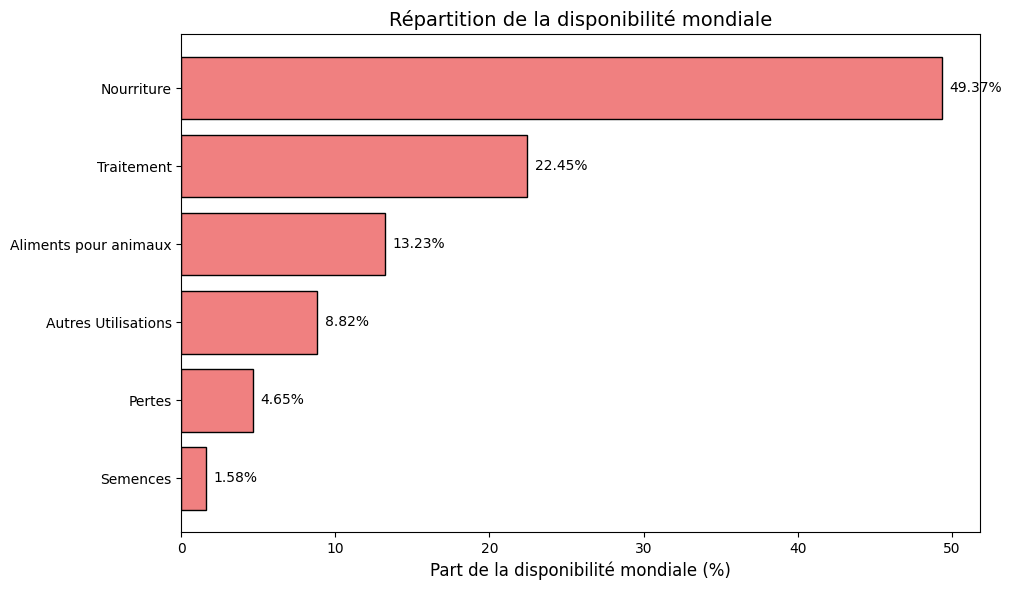

In [46]:
colonnes = ['Aliments pour animaux', 'Nourriture', 'Pertes', 'Semences', 'Traitement', 'Autres Utilisations']

# Calcul des pourcentages pour chaque colonne
valeurs = [
round((dispo_alimentaire_population_2017[colonne].sum() / disponibilité_totale) * 100, 2)
for colonne in colonnes
]

# Trie des colonnes et valeurs en fonction des pourcentages
colonnes_valeurs = sorted(zip(valeurs, colonnes), reverse=False)
valeurs_triees, colonnes_triees = zip(*colonnes_valeurs)

# Création du graphique à barres horizontales
plt.figure(figsize=(10, 6))
plt.barh(colonnes_triees, valeurs_triees, color='lightcoral', edgecolor='black')

# Ajout des labels et du titre
plt.xlabel("Part de la disponibilité mondiale (%)", fontsize=12)
plt.title("Répartition de la disponibilité mondiale", fontsize=14)
plt.tight_layout()

# Affichage des valeurs à droite des barres
for i, v in enumerate(valeurs_triees):
    plt.text(v + 0.5, i, f"{v}%", va='center', fontsize=10)

# Exportation de l'image
plt.savefig("3.4.png", dpi=300, bbox_inches='tight')

# Afficher le graphique
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.5 - Utilisation des céréales</h3>
</div>

In [47]:
#Création d'une liste avec les principaux céréales
cereales = ['Blé', 'Riz (Eq Blanchi)', 'Orge', 'Maïs', 'Seigle', 'Avoine', 'Millet', 'Sorgho', 'Céréales', 'Autres']

In [48]:
#Création d'un dataframe avec les informations uniquement pour ces céréales
dispo_alimentaire_population_cereales_2017 =  dispo_alimentaire_population_2017[dispo_alimentaire_population_2017['Produit'].isin(cereales)]
print(dispo_alimentaire_population_cereales_2017)

              Zone  Année  Population           Produit   Origine  \
247    Afghanistan   2017  36296113.0               Blé  vegetale   
272    Afghanistan   2017  36296113.0              Maïs  vegetale   
274    Afghanistan   2017  36296113.0            Millet  vegetale   
280    Afghanistan   2017  36296113.0              Orge  vegetale   
287    Afghanistan   2017  36296113.0  Riz (Eq Blanchi)  vegetale   
...            ...    ...         ...               ...       ...   
92362     Zimbabwe   2017  14236595.0            Millet  vegetale   
92370     Zimbabwe   2017  14236595.0              Orge  vegetale   
92387     Zimbabwe   2017  14236595.0  Riz (Eq Blanchi)  vegetale   
92388     Zimbabwe   2017  14236595.0            Seigle  vegetale   
92390     Zimbabwe   2017  14236595.0            Sorgho  vegetale   

       Aliments pour animaux  Autres Utilisations  \
247                      0.0                  0.0   
272                 200000.0                  0.0   
274         

In [49]:
#Affichage de la proportion d'alimentation animale
cereales_alimentation_animale = dispo_alimentaire_population_cereales_2017['Aliments pour animaux'].sum()
print(cereales_alimentation_animale)

840833000.0


In [50]:
#Affichage de la proportion d'alimentation humaine
cereales_alimentation_humaine = dispo_alimentaire_population_cereales_2017['Nourriture'].sum()
print(cereales_alimentation_humaine)

1015156000.0


In [51]:
proportion_cereales_alimentation_animale = round(cereales_alimentation_animale / (cereales_alimentation_animale + cereales_alimentation_humaine)*100,2)
print(proportion_cereales_alimentation_animale)

45.3


In [52]:
proportion_cereales_alimentation_humaine = round(cereales_alimentation_humaine / (cereales_alimentation_humaine + cereales_alimentation_animale)*100,2)
print(proportion_cereales_alimentation_humaine)

54.7


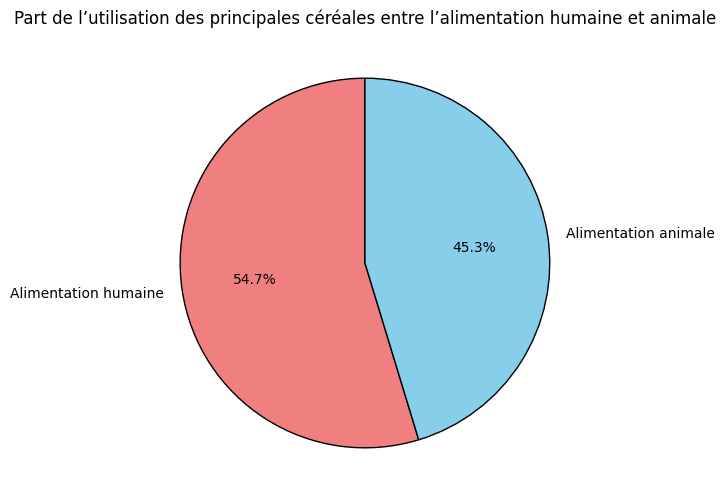

In [53]:
# Calcul des parts du diagramme circulaire
data = [proportion_cereales_alimentation_humaine, proportion_cereales_alimentation_animale]
labels = ['Alimentation humaine', 'Alimentation animale']
colors = ['lightcoral', 'skyblue']

# Création du diagramme circulaire
plt.figure(figsize=(6, 6))
plt.pie(data, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors, wedgeprops={'edgecolor': 'black'})
plt.title("Part de l’utilisation des principales céréales entre l’alimentation humaine et animale")

# Exportation de l'image
plt.savefig("3.5.png", dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.6 - Pays avec la proportion de personnes sous-alimentée la plus forte en 2017</h3>
</div>

In [54]:
# Copie de proportion_sous_nutrition_2017
proportion_sous_nutrition_2017 = proportion_sous_nutrition_2017.copy()

proportion_sous_nutrition_2017.loc[:, 'proportion_sous_nutrition'] = (
proportion_sous_nutrition_2017['sous_nutrition'] / proportion_sous_nutrition_2017['Population']
) * 100

In [55]:
#Création de la colonne proportion par pays et affichage après trie des 10 pires pays
print(
    proportion_sous_nutrition_2017[['Zone', 'proportion_sous_nutrition']]
    .sort_values(by='proportion_sous_nutrition', ascending=False)
    .head(10)
)

                                            Zone  proportion_sous_nutrition
2836                                       Haïti                  48.259182
5680  République populaire démocratique de Corée                  47.188685
3916                                  Madagascar                  41.062924
3736                                     Libéria                  38.279742
3628                                     Lesotho                  38.249438
6616                                       Tchad                  37.957606
5824                                      Rwanda                  35.055619
4384                                  Mozambique                  32.810898
6724                                 Timor-Leste                  32.173531
28                                   Afghanistan                  28.928718


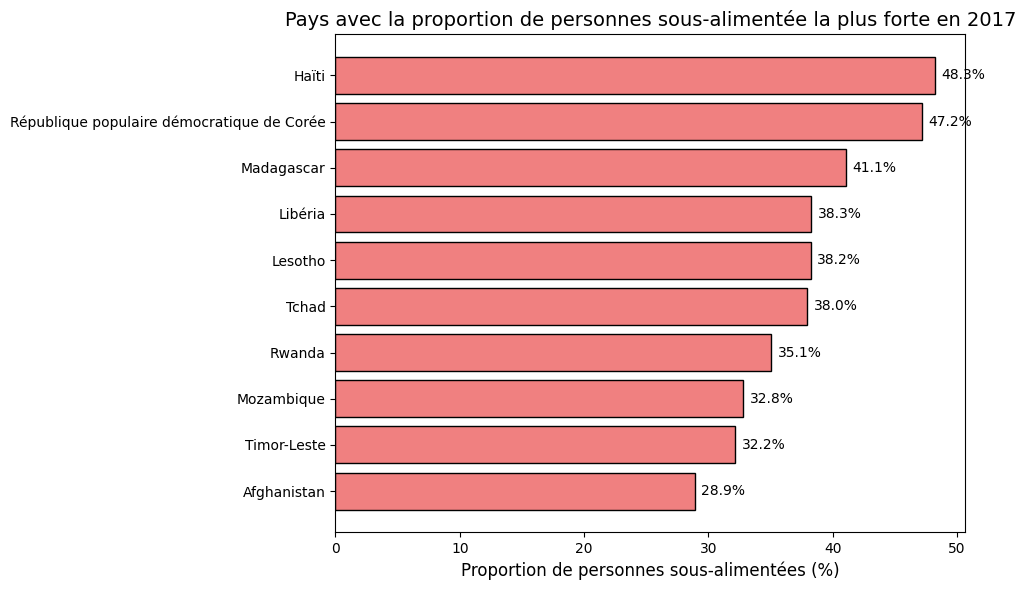

In [56]:
top_10_sous_alimentation = proportion_sous_nutrition_2017.sort_values(by='proportion_sous_nutrition', ascending=False).head(10)

# Création du graphique à barres
plt.figure(figsize=(10, 6))
plt.barh(top_10_sous_alimentation['Zone'], top_10_sous_alimentation['proportion_sous_nutrition'], color='lightcoral', edgecolor = 'black')

# Ajout des titres et labels
plt.title("Pays avec la proportion de personnes sous-alimentée la plus forte en 2017", fontsize=14)
plt.xlabel("Proportion de personnes sous-alimentées (%)", fontsize=12)
plt.gca().invert_yaxis()  # Inversion de l'axe Y pour que le pays avec la pire proportion soit en haut

# Ajout des annotations sur les barres
for i, value in enumerate(top_10_sous_alimentation['proportion_sous_nutrition']):
    plt.text(value + 0.5, i, f'{value:.1f}%', va='center', fontsize=10)

# Affichage du graphique
plt.tight_layout()
plt.savefig("3.6.png", dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.7 - Pays qui ont le plus bénéficié d'aide alimentaire depuis 2013</h3>
</div>

In [57]:
#calcul du total de l'aide alimentaire par pays et affichage après trie des 10 pays qui ont bénéficié le plus de l'aide alimentaire
somme_par_zone = aide_alimentaire.groupby('Zone')['Valeur'].sum().reset_index()
somme_par_zone = somme_par_zone.sort_values(by='Valeur', ascending=False)
print(somme_par_zone.head(10))

                                Zone      Valeur
50         République arabe syrienne  1858943000
75                          Éthiopie  1381294000
70                             Yémen  1206484000
61                     Soudan du Sud   695248000
60                            Soudan   669784000
30                             Kenya   552836000
3                         Bangladesh   348188000
59                           Somalie   292678000
53  République démocratique du Congo   288502000
43                             Niger   276344000


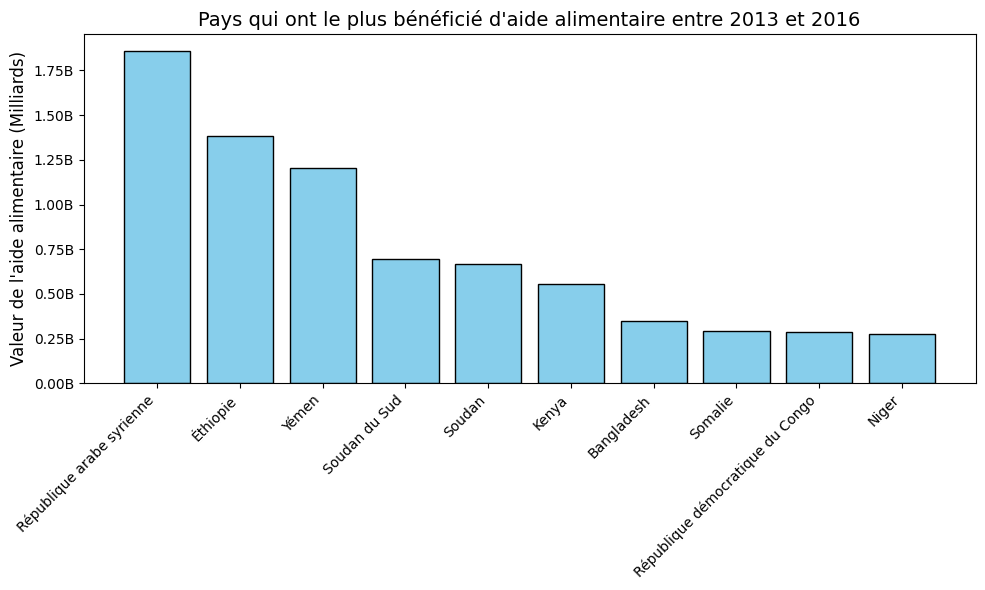

In [58]:
top_10_aide_alimentaire = somme_par_zone.sort_values(by='Valeur', ascending=False).head(10)

plt.figure(figsize=(10, 6))
bars = plt.bar(top_10_aide_alimentaire['Zone'], top_10_aide_alimentaire['Valeur'], color='skyblue', edgecolor = 'black')

# Ajout des titres et labels
plt.title("Pays qui ont le plus bénéficié d'aide alimentaire entre 2013 et 2016", fontsize=14)
plt.ylabel("Valeur de l'aide alimentaire (Milliards)", fontsize=12)

# Affichage du graphique
plt.xticks(rotation=45, ha="right")  # Rotation des labels de l'axe X pour plus de lisibilité
plt.tight_layout()
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x / 1e9:.2f}B'))
plt.savefig("3.7.png", dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.8 - Evolution des 5 pays qui ont le plus bénéficiés de l'aide alimentaire entre 2013 et 2016</h3>
</div>

In [59]:
#Création d'une liste contenant les 5 pays qui ont le plus bénéficiées de l'aide alimentaire
top_5_zones = somme_par_zone.head(5)['Zone'].tolist()

# Afficher la liste
print(top_5_zones)

['République arabe syrienne', 'Éthiopie', 'Yémen', 'Soudan du Sud', 'Soudan']


In [60]:
#Création d'un dataframe avec la zone, l'année et l'aide alimentaire puis groupby sur zone et année 
aide_alimentaire_2013_2016 = aide_alimentaire[['Zone', 'Année', 'Valeur']]
groupby_aide_alimentaire_2013_2016 = aide_alimentaire_2013_2016.groupby(['Zone', 'Année']).sum().reset_index()

In [61]:
#On filtre sur le dataframe avec notre liste
groupby_aide_alimentaire_2013_2016_5_pays = groupby_aide_alimentaire_2013_2016[groupby_aide_alimentaire_2013_2016['Zone'].isin(top_5_zones)]

In [62]:
# Affichage des pays avec l'aide alimentaire par année
print(groupby_aide_alimentaire_2013_2016_5_pays)

                          Zone  Année     Valeur
157  République arabe syrienne   2013  563566000
158  République arabe syrienne   2014  651870000
159  République arabe syrienne   2015  524949000
160  République arabe syrienne   2016  118558000
189                     Soudan   2013  330230000
190                     Soudan   2014  321904000
191                     Soudan   2015   17650000
192              Soudan du Sud   2013  196330000
193              Soudan du Sud   2014  450610000
194              Soudan du Sud   2015   48308000
214                      Yémen   2013  264764000
215                      Yémen   2014  103840000
216                      Yémen   2015  372306000
217                      Yémen   2016  465574000
225                   Éthiopie   2013  591404000
226                   Éthiopie   2014  586624000
227                   Éthiopie   2015  203266000


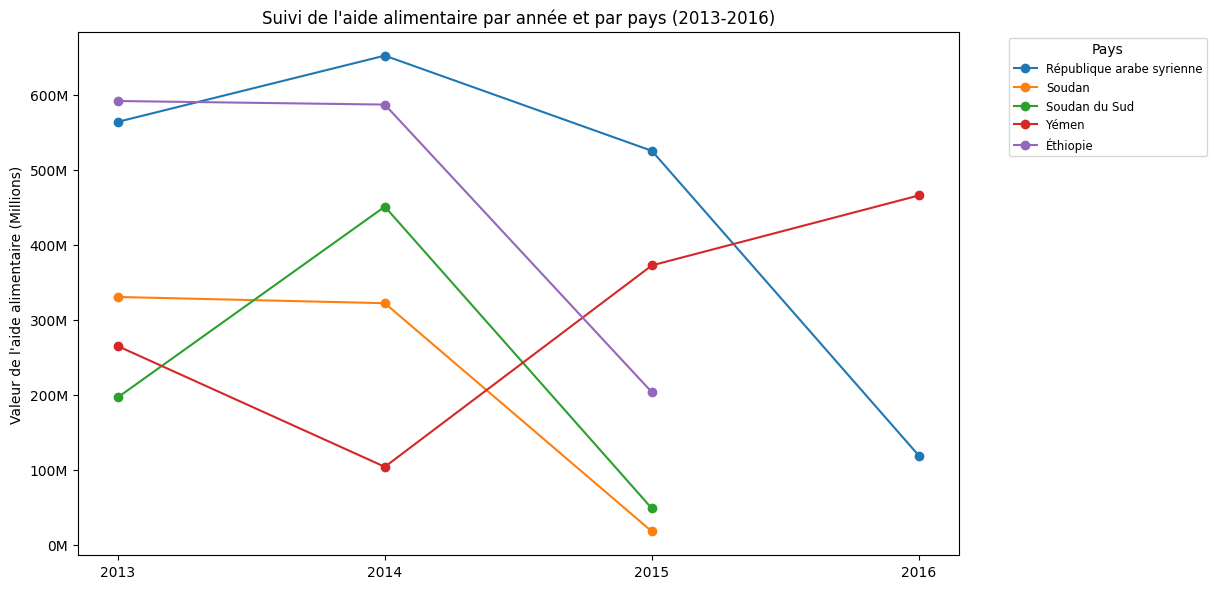

In [63]:
# Créer une figure et des axes
plt.figure(figsize=(12, 6))

# Tracer une courbe pour chaque pays
for zone in groupby_aide_alimentaire_2013_2016_5_pays['Zone'].unique():
    # Filtrer les données pour le pays en question
    data_pays = groupby_aide_alimentaire_2013_2016_5_pays[groupby_aide_alimentaire_2013_2016_5_pays['Zone'] == zone]
    
    # Tracer la courbe
    plt.plot(data_pays['Année'], data_pays['Valeur'], label=zone, marker='o')

# Ajouter des labels et un titre
plt.ylabel("Valeur de l'aide alimentaire (Millions)")
plt.title("Suivi de l'aide alimentaire par année et par pays (2013-2016)")

# Ajouter une légende
plt.legend(title="Pays", loc='upper left', bbox_to_anchor=(1.05, 1), fontsize='small')

# Ajuster le layout pour éviter la coupure de la légende
plt.tight_layout()

# Formatter l'axe Y
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x / 1e6:.0f}M'))

# Récupérer les ticks actuels
ticks, tick_labels = plt.xticks()

# Filtrer les ticks pour ne garder que ceux dont l'indice est pair
filtered_ticks = ticks[1::2]  # Commencer à l'indice 1 pour garder les pairs
filtered_tick_labels = [tick_labels[i].get_text() for i in range(1, len(tick_labels), 2)]

# Modifier les labels pour supprimer la décimale
filtered_tick_labels = [str(int(float(label))) for label in filtered_tick_labels]

# Appliquer les nouveaux ticks avec les labels modifiés
plt.xticks(filtered_ticks, filtered_tick_labels)

# Exporter le graphique
plt.savefig("3.8.png", dpi=300, bbox_inches='tight')

# Afficher le graphique
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.9 - Pays avec le moins de disponibilité par habitant</h3>
</div>

In [68]:
#Calcul de la disponibilité en kcal par personne par jour par pays
disponibilite_alimentaire_par_pays = (
    dispo_alimentaire_population_2017.groupby('Zone')['Disponibilité alimentaire (Kcal/personne/jour)']
    .sum()
    .reset_index()
)

In [69]:
#Affichage des 10 pays qui ont le moins de dispo alimentaire par personne 
disponibilite_alimentaire_par_pays = disponibilite_alimentaire_par_pays.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=True)
print(disponibilite_alimentaire_par_pays.head(10))

                                           Zone  \
127                   République centrafricaine   
164                                      Zambie   
91                                   Madagascar   
0                                   Afghanistan   
65                                        Haïti   
132  République populaire démocratique de Corée   
150                                       Tchad   
165                                    Zimbabwe   
114                                     Ouganda   
152                                 Timor-Leste   

     Disponibilité alimentaire (Kcal/personne/jour)  
127                                          1879.0  
164                                          1924.0  
91                                           2056.0  
0                                            2087.0  
65                                           2089.0  
132                                          2093.0  
150                                          2109.0  
165   

In [70]:
moyenne_disponibilite_mondiale = round(disponibilite_alimentaire_par_pays['Disponibilité alimentaire (Kcal/personne/jour)'].mean(),0)
print(moyenne_disponibilite_mondiale)

2842.0


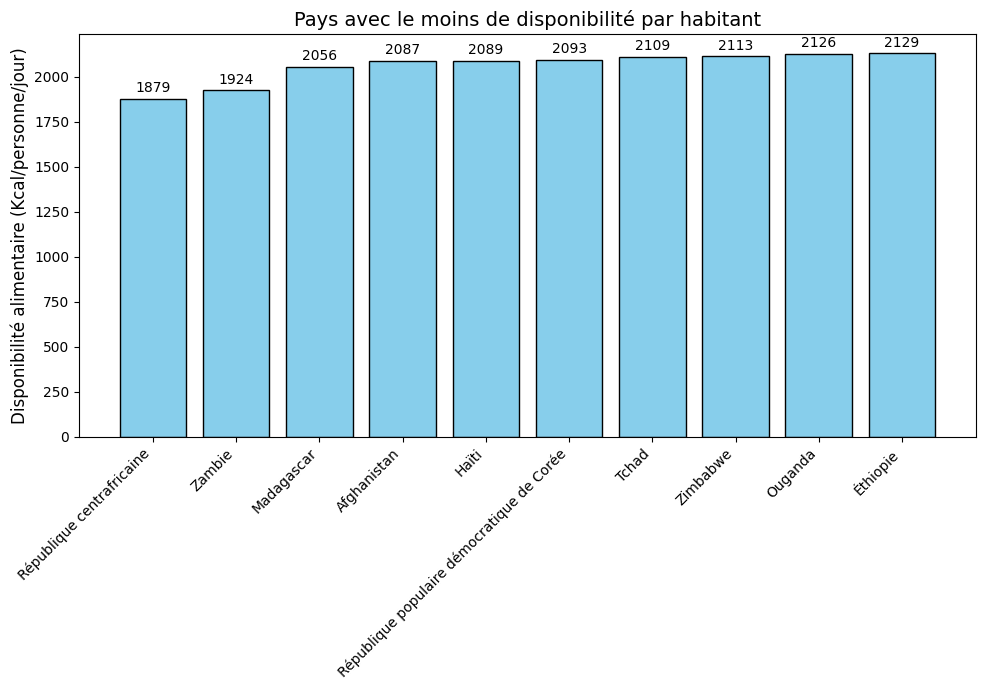

In [71]:
top_10_moins_disponibilite = disponibilite_alimentaire_par_pays.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=True).head(10)

# Création du graphique à barres
plt.figure(figsize=(10, 7))
plt.bar(top_10_moins_disponibilite['Zone'], top_10_moins_disponibilite['Disponibilité alimentaire (Kcal/personne/jour)'], color='skyblue', edgecolor = 'black')

# Ajout des titres et labels
plt.title("Pays avec le moins de disponibilité par habitant", fontsize=14)
plt.ylabel("Disponibilité alimentaire (Kcal/personne/jour)", fontsize=12)

# Ajout des annotations sur les barres
for i, value in enumerate(top_10_moins_disponibilite['Disponibilité alimentaire (Kcal/personne/jour)']):
    plt.text(i, value + 20, f'{value:.0f}', ha='center', va='bottom', fontsize=10)

# Affichage du graphique
plt.xticks(rotation=45, ha="right")  # Rotation des labels de l'axe X pour plus de lisibilité
plt.tight_layout()
plt.savefig("3.9.png", dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.10 - Pays avec le plus de disponibilité par habitant</h3>
</div>

In [72]:
#Affichage des 10 pays qui ont le plus de dispo alimentaire par personne 
disponibilite_alimentaire_par_pays = disponibilite_alimentaire_par_pays.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=False)
print(disponibilite_alimentaire_par_pays.head(10))

                      Zone  Disponibilité alimentaire (Kcal/personne/jour)
11                Autriche                                          3770.0
16                Belgique                                          3737.0
157                Turquie                                          3708.0
169  États-Unis d'Amérique                                          3682.0
74                  Israël                                          3610.0
72                 Irlande                                          3602.0
75                  Italie                                          3578.0
89              Luxembourg                                          3540.0
166                 Égypte                                          3518.0
4                Allemagne                                          3503.0


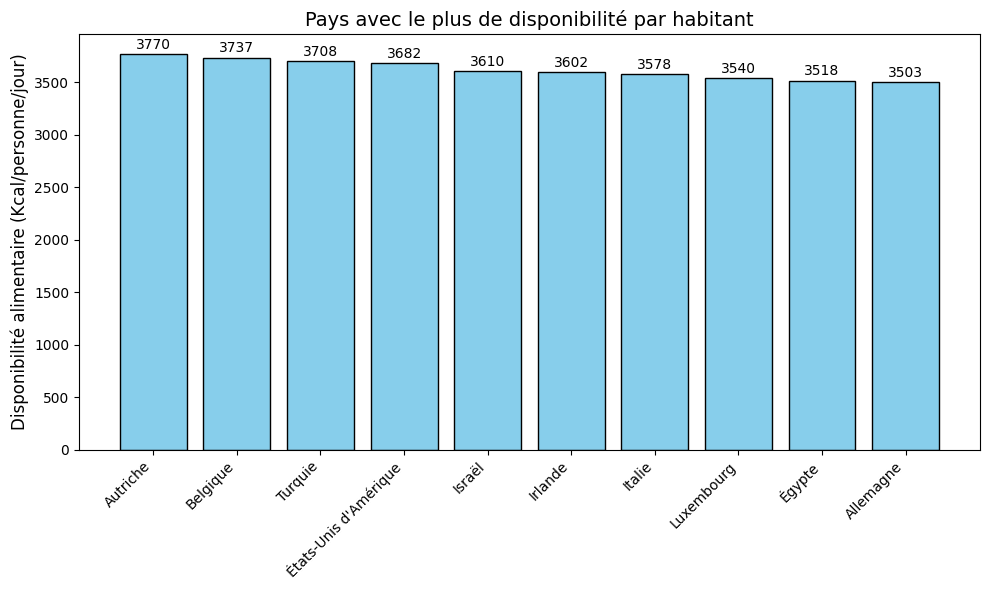

In [73]:
top_10_plus_disponibilite = disponibilite_alimentaire_par_pays.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=False).head(10)

# Création du graphique à barres
plt.figure(figsize=(10, 6))
plt.bar(top_10_plus_disponibilite['Zone'], top_10_plus_disponibilite['Disponibilité alimentaire (Kcal/personne/jour)'], color='skyblue', edgecolor = 'black')

# Ajout des titres et labels
plt.title("Pays avec le plus de disponibilité par habitant", fontsize=14)
plt.ylabel("Disponibilité alimentaire (Kcal/personne/jour)", fontsize=12)

# Ajout des annotations sur les barres
for i, value in enumerate(top_10_plus_disponibilite['Disponibilité alimentaire (Kcal/personne/jour)']):
    plt.text(i, value + 20, f'{value:.0f}', ha='center', va='bottom', fontsize=10)

# Affichage du graphique
plt.xticks(rotation=45, ha="right")  # Rotation des labels de l'axe X pour plus de lisibilité
plt.tight_layout()
plt.savefig("3.10.png", dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.11 - Exemple de la Thaïlande pour le Manioc</h3>
</div>

In [74]:
# Il faut tout d'abord faire une jointure entre la table population et la table sous nutrition, en ciblant l'année 2017
proportion_sous_nutrition_thaïlande = pd.merge(population, sous_nutrition, on='Zone', how='inner')
proportion_sous_nutrition_2017_thaïlande = proportion_sous_nutrition_thaïlande[
    (proportion_sous_nutrition_thaïlande['Année_y'] == '2016-2018') & (proportion_sous_nutrition_thaïlande['Année_x'] == 2017) & (proportion_sous_nutrition_thaïlande['Zone'] == 'Thaïlande')]

In [75]:
nombre_personnes_sous_nutrition_thaïlande = round(proportion_sous_nutrition_2017_thaïlande['sous_nutrition'].sum())
indicateur_sous_nutrition_thaïlande = round((proportion_sous_nutrition_2017_thaïlande['sous_nutrition'].sum() / proportion_sous_nutrition_2017_thaïlande['Population'].sum())*100,2)
print(f"Le nombre d'humains en sous-nutrition en Thaïlande est de : {nombre_personnes_sous_nutrition_thaïlande}, cela correspond à {indicateur_sous_nutrition_thaïlande}% de la population thaïlandaise.")

Le nombre d'humains en sous-nutrition en Thaïlande est de : 6200000, cela correspond à 8.96% de la population thaïlandaise.


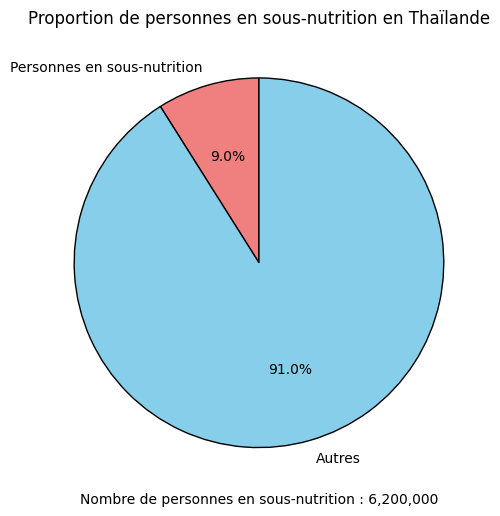

In [76]:
# Calcul des parts du diagramme circulaire
data = [indicateur_sous_nutrition_thaïlande, 100 - indicateur_sous_nutrition_thaïlande]
labels = ['Personnes en sous-nutrition', 'Autres']
colors = ['lightcoral', 'skyblue']

# Création du diagramme circulaire
plt.figure(figsize=(6, 6))
plt.pie(data, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors, wedgeprops={'edgecolor': 'black'})
plt.title("Proportion de personnes en sous-nutrition en Thaïlande")
plt.text(0, -1.3, f"Nombre de personnes en sous-nutrition : {nombre_personnes_sous_nutrition_thaïlande:,}",
         ha='center', fontsize=10, color='black')

plt.savefig("3.11.1.png", dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

In [77]:
thailande_manioc_2017 = dispo_alimentaire_population_2017[(dispo_alimentaire_population_2017['Zone'] == 'Thaïlande') & (dispo_alimentaire_population_2017['Produit'] == 'Manioc')]

In [78]:
exportation_thailande = (thailande_manioc_2017['Exportations - Quantité'].sum()/1000000)
production_thailande = (thailande_manioc_2017['Production'].sum()/1000000)

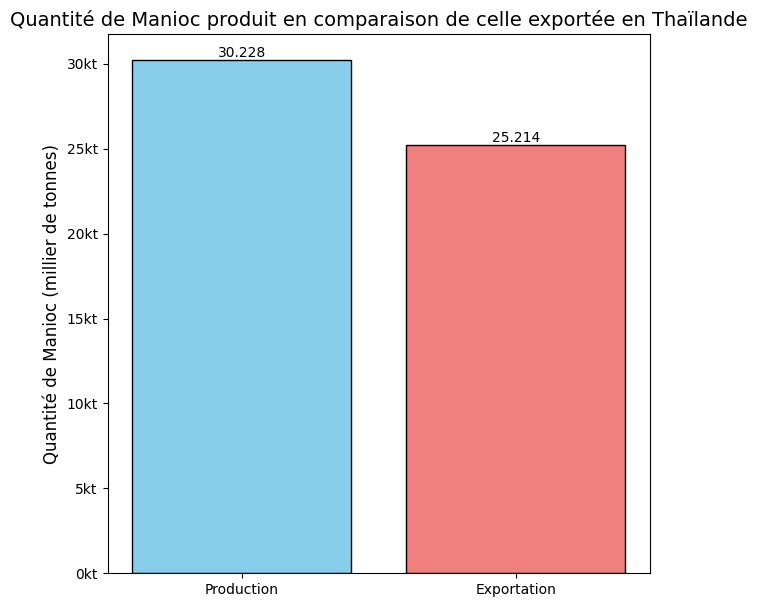

In [79]:
# Données pour le graphique
categories = ['Production', 'Exportation']
valeurs = [production_thailande, exportation_thailande]
colors = ['skyblue', 'lightcoral']

# Création du graphique à barres
plt.figure(figsize=(7, 7))
bars = plt.bar(categories, valeurs, color=colors, edgecolor = 'black')

# Ajout des valeurs sur les barres
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height, f'{height:,}', ha='center', va='bottom', fontsize=10)

# Titre et labels
plt.title("Quantité de Manioc produit en comparaison de celle exportée en Thaïlande", fontsize=14)
plt.ylabel("Quantité de Manioc (millier de tonnes)", fontsize=12)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x / 1e0:.0f}kt'))

# Exportation de l'image
plt.savefig("3.11.2.png", dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

In [80]:
disponibilite_alimentaire_thaïlande = disponibilite_alimentaire_par_pays[disponibilite_alimentaire_par_pays['Zone'] == 'Thaïlande']
indicateur_disponibilite_alimentaire_thaïlande = disponibilite_alimentaire_thaïlande['Disponibilité alimentaire (Kcal/personne/jour)'].iloc[0]
print(indicateur_disponibilite_alimentaire_thaïlande)

2785.0


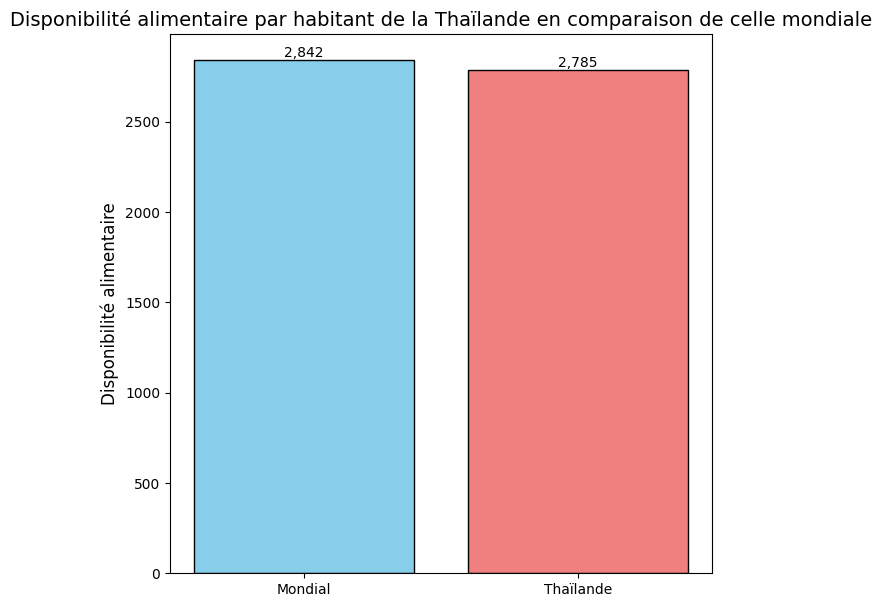

In [81]:
# Données pour le graphique
categories = ['Mondial', 'Thaïlande']
valeurs = [moyenne_disponibilite_mondiale, indicateur_disponibilite_alimentaire_thaïlande]
colors = ['skyblue', 'lightcoral']

# Création du graphique à barres
plt.figure(figsize=(7, 7))
bars = plt.bar(categories, valeurs, color=colors, edgecolor = 'black')

# Ajout des valeurs sur les barres
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height, f'{int(height):,}', ha='center', va='bottom', fontsize=10)

# Titre et labels
plt.title("Disponibilité alimentaire par habitant de la Thaïlande en comparaison de celle mondiale", fontsize=14)
plt.ylabel("Disponibilité alimentaire", fontsize=12)

# Exportation de l'image
plt.savefig("3.11.3.png", dpi=300, bbox_inches='tight')

# Affichage du graphique
plt.show()

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 6 - Analyse complémentaires</h2>
</div>

In [82]:
# Charger les fichiers CSV sans noms de colonnes
population = pd.read_csv('population.csv', encoding='utf-8')
sql_pays = pd.read_csv('sql-pays.csv', encoding='utf-8', header=None) # fichier csv qui répertorie le code ISO des pays du monde entier (une grande partie)

# Attribuer des noms aux colonnes de sql-pays
sql_pays.columns = ['ID', 'Code', 'Code2', 'ISO_Code', 'Zone', 'Name']

# Copie du dataframe proportion_sous_nutrition_2017
proportion_nutrition_carte = proportion_sous_nutrition_2017.copy()
proportion_nutrition_carte['indicateur_sous_nutrition'] = round((proportion_nutrition_carte['sous_nutrition'] / proportion_nutrition_carte['Population']) * 100, 2)

# Normaliser les noms (enlever les espaces et mettre tout en minuscule pour la comparaison)
proportion_nutrition_carte.loc[:, 'Zone'] = proportion_nutrition_carte['Zone'].str.strip().str.lower()
sql_pays.loc[:, 'Zone'] = sql_pays['Zone'].str.strip().str.lower()

# Joindre les données de proportion_nutrition_carte avec le code ISO obtenu à l'aide du fichier sql-pays
merged_df = pd.merge(proportion_nutrition_carte, sql_pays[['Zone', 'ISO_Code']], left_on='Zone', right_on='Zone', how='left')

# Identifier les pays sans code ISO après la jointure
missing_iso = merged_df[merged_df['ISO_Code'].isna()]

# Liste des remplacements manuels pour les codes ISO manquants (pour les pays où on ne récupère pas le code ISO, on tente de le compléter manuellement)
replacements = {
    'antilles néerlandaises (ex)': 'NLD',
    'bolivie (état plurinational de)': 'BOL',
    'bonaire, saint-eustache et saba': 'BES',
    'cabo verde': 'CPV',
    'chine - ras de hong-kong': 'HKG',
    'chine - ras de macao': 'MAC',
    'chine, continentale': 'CHN',
    'chine, taiwan province de': 'TWN',
    'congo': 'COG',
    'curaçao': 'CUW',
    'eswatini': 'SWZ',
    'états-unis d\'amérique': 'USA',
    'îles anglo-normandes': 'GGY',
    'îles falkland (malvinas)': 'FLK',
    'îles turques-et-caïques': 'TCA',
    'îles vierges américaines': 'VIR',
    'îles wallis-et-futuna': 'WLF',
    "iran (république islamique d')": 'IRN',
    'libye': 'LBY',
    'macédoine du nord': 'MKD',
    'micronésie (états fédérés de)': 'FSM',
    'monténégro': 'MNE',
    'nioué': 'NIU',
    'palestine': 'PSE',
    'royaume-uni de grande-bretagne et d\'irlande du nord': 'GBR',
    'saint-barthélemy': 'BLM',
    'sainte-hélène, ascension et tristan da cunha': 'SHN',
    'saint-martin (partie française)': 'SXM',
    'saint-siège': 'VAT',
    'serbie': 'SRB',
    'sint maarten  (partie néerlandaise)': 'SXM',
    'soudan du sud': 'SSD',
    'tchéquie': 'CZE',
    'tokélaou': 'TKL',
    'venezuela (république bolivarienne du)': 'VEN'
}

# Appliquer les remplacements manuels
for country, iso_code in replacements.items():
    merged_df.loc[merged_df['Zone'] == country, 'ISO_Code'] = iso_code

# Vérifier les remplacements effectués
print("DataFrame après remplacement des codes ISO manuellement :")
print(merged_df[merged_df['ISO_Code'].isin(replacements.values())])

# Afficher le DataFrame final
print("DataFrame final après toutes les modifications :")
print(merged_df)


DataFrame après remplacement des codes ISO manuellement :
                                                  Zone  Année_x    Population  \
24                     bolivie (état plurinational de)     2017  1.119286e+07   
32                                          cabo verde     2017  5.374980e+05   
37                            chine - ras de hong-kong     2017  7.306322e+06   
38                                chine - ras de macao     2017  6.225850e+05   
39                                 chine, continentale     2017  1.421022e+09   
40                           chine, taiwan province de     2017  2.367455e+07   
44                                               congo     2017  5.110695e+06   
59                                            eswatini     2017  1.124805e+06   
60                               états-unis d'amérique     2017  3.250848e+08   
86                      iran (république islamique d')     2017  8.067388e+07   
104                                              li

In [84]:
# Pour obtenir la forme des pays sur la carte du Monde, on se base sur des fichiers GeoJSON, je me base sur un github pour cela, voici l'URL
base_url = "https://raw.githubusercontent.com/johan/world.geo.json/master/countries/"

# Fonction pour déterminer la couleur en fonction de la valeur
def definition_couleur(value, colormap):
    return colormap(value)

# Créer une carte centrée sur le centre du monde (latitude 0, longitude 0)
carte = folium.Map(location=[0, 0], zoom_start=2)

# Créer une colormap allant du blanc (faible taux de sous-nutriton) au rouge (fort taux de sous-nutriton)
colormap = linear.OrRd_09.scale(0, 50)  # Plage de valeurs de 0 à 50 (pour le taux de sous-nutrition)
colormap.caption = 'Proportion de sous-nutrition'  # Ajouter un label à la colorbar

# Ajouter la colorbar à la carte
carte.add_child(colormap)

# Ajouter chaque pays à la carte en utilisant le code ISO directement
for index, row in merged_df.iterrows():
    country = row['Zone']  # Utiliser le nom du pays dans le DataFrame
    value = row['indicateur_sous_nutrition']  # Utiliser la colonne correcte pour la valeur
    country_code = row['ISO_Code']  # Utiliser le code ISO du DataFrame
    
    # Construire l'URL en utilisant le code ISO
    url = f"{base_url}{country_code}.geo.json"
    
    try:
        # Récupérer les données GeoJSON via le github
        response = requests.get(url)
        response.raise_for_status()  # Vérifier que la requête a réussi
        
        geojson = response.json()  # Convertir la réponse en JSON
        
        # Ajouter les frontières du pays à la carte avec la couleur correspondant à sa valeur
        folium.GeoJson(geojson, name=country,
                       style_function=lambda feature, value=value, colormap=colormap: {
                           'fillColor': definition_couleur(value, colormap),
                           'color': 'black', 'weight': 1}).add_to(carte)
        
    # Ici on affiche les erreurs rencontrées pour certains pays, cela peut-être dû à un URL manquant sur le github (pays non disponible sur le github ou renseignement manuel du code ISO qui n'est pas bon), un mauvais fichier dans le github ou autre
    except requests.exceptions.RequestException as e:
        print(f"Erreur lors de la récupération du fichier GeoJSON pour {country} ({country_code}): {e}")
    except ValueError as e:
        print(f"Erreur de format JSON pour {country} ({country_code}): {e}")
    except Exception as e:
        print(f"Autre erreur pour {country} ({country_code}): {e}")

# Enregistrer la carte dans un fichier HTML
carte.save("Carte_représentative_du_taux_de_sous_nutrition_dans_le_Monde.html")

# Ouvrir la carte dans un navigateur
import webbrowser
webbrowser.open("Carte_représentative_du_taux_de_sous_nutrition_dans_le_Monde.html")


Erreur lors de la récupération du fichier GeoJSON pour andorre (AND): 404 Client Error: Not Found for url: https://raw.githubusercontent.com/johan/world.geo.json/master/countries/AND.geo.json
Erreur lors de la récupération du fichier GeoJSON pour antigua-et-barbuda (ATG): 404 Client Error: Not Found for url: https://raw.githubusercontent.com/johan/world.geo.json/master/countries/ATG.geo.json
Erreur lors de la récupération du fichier GeoJSON pour bahreïn (BHR): 404 Client Error: Not Found for url: https://raw.githubusercontent.com/johan/world.geo.json/master/countries/BHR.geo.json
Erreur lors de la récupération du fichier GeoJSON pour barbade (BRB): 404 Client Error: Not Found for url: https://raw.githubusercontent.com/johan/world.geo.json/master/countries/BRB.geo.json
Erreur lors de la récupération du fichier GeoJSON pour cabo verde (CPV): 404 Client Error: Not Found for url: https://raw.githubusercontent.com/johan/world.geo.json/master/countries/CPV.geo.json
Erreur lors de la récupéra

True